# Learning a soil's diffusivity with a neural network

In this tutorial, we follow water as it soaks into dry soil at a rate set by the moisture diffusivity $D(\theta)$, which measures how fast water spreads. The diffusivity grows by orders of magnitude as the soil wets. We learn $D(\theta)$ as a small neural network inside the PDE and train it through the solve on moisture profiles from several experiments ([function approximation](../overview/inference/function-approximation.md#neural-networks)). The setup is the horizontal infiltration experiment of [Bruce and Klute (1956)](https://doi.org/10.2136/sssaj1956.03615995002000040004x). The truth is the diffusivity of a loam, the ordinary garden soil that mixes sand and silt with a smaller share of clay, from the [van Genuchten (1980)](https://doi.org/10.2136/sssaj1980.03615995004400050002x) model.

## Setup

We build the network, a small fully connected multilayer perceptron, with [Equinox](https://docs.kidger.site/equinox/) and take the optimizer from [Optax](https://optax.readthedocs.io/). The config cell picks the sizes from the device and runs the 1D work on the CPU, for the reason the last section shows.

In [1]:
import diff_soup as ds                            # first, so JAX starts with diff-soup's settings
from diff_soup.domains import cartesian_grid_1d, cartesian_grid_2d

import time

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
CPU = jax.devices("cpu")[0]
jax.config.update("jax_default_device", CPU)     # the 1D work runs on the CPU
N = 64                                           # cells along the 1D column
STEPS = 400                                      # Adam steps per training run
SIZES = {1: (64, 256, 1024), 2: (32, 64, 128) + ((256,) if GPU else ())}   # timed at the end
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0]}")

diff-soup 1.1.0, JAX 0.11.2, cuda:0


## The problem

We consider a horizontal soil column, $0 < x < L$ with $L = 20$ cm, that starts dry and whose left end is held wet for six hours from $t = 0$. The water content $\theta(x, t)$, the fraction of the soil's volume taken up by water, follows Richards' equation for water flow in soil, here without gravity,

$$
\frac{\partial \theta}{\partial t} = \frac{\partial}{\partial x}\Big(D(\theta)\,\frac{\partial \theta}{\partial x}\Big),
\qquad \theta(0, t) = \theta_b, \qquad \frac{\partial \theta}{\partial x}(L, t) = 0, \qquad \theta(x, 0) = \theta_i .
$$

The true diffusivity is the van Genuchten-Mualem law, a standard fit to measured soils,

$$
D(S) = \frac{(1 - m)\,K_s}{\alpha\, m\,(\theta_s - \theta_r)}\; S^{1/2 - 1/m}
\Big[\big(1 - S^{1/m}\big)^{-m} + \big(1 - S^{1/m}\big)^{m} - 2\Big],
$$

where $S = (\theta - \theta_r)/(\theta_s - \theta_r)$ is the effective saturation, which runs from 0 for the driest to 1 for fully wet soil and starts at $S_i = 0.2$. We take the loam of [Carsel and Parrish (1988)](https://doi.org/10.1029/WR024i005p00755), with residual and saturated water contents $\theta_r = 0.078$ and $\theta_s = 0.43$. Its other constants are $\alpha = 0.036$ cm$^{-1}$, $m = 1 - 1/1.56$ and the saturated conductivity $K_s = 1.04$ cm/h.

In [2]:
L, T = 20.0, 6.0                                  # column length (cm), duration (h)
theta_r, theta_s = 0.078, 0.43                    # residual and saturated water content
alpha, m, K_s = 0.036, 1 - 1 / 1.56, 1.04         # 1/cm, dimensionless, cm/h
S_i = 0.2                                         # initial effective saturation


def to_theta(S):
    return theta_r + (theta_s - theta_r) * S


def saturation(theta):
    return (theta - theta_r) / (theta_s - theta_r)


def D_true(S):
    s = S ** (1 / m)
    return (1 - m) * K_s / (alpha * m * (theta_s - theta_r)) * S ** (0.5 - 1 / m) * ((1 - s) ** -m + (1 - s) ** m - 2)


print(f"D(0.2) = {D_true(0.2):.3f} cm^2/h, D(0.9) = {D_true(0.9):.1f} cm^2/h")

D(0.2) = 0.096 cm^2/h, D(0.9) = 45.9 cm^2/h


Between the driest and the wettest soil here, $D$ grows about 500-fold.

## Build the model

First, we write one function that builds the column for a given diffusivity. In it, `spec.function` declares $D$ as a named function, called as `q.fn.D`, and `pointwise=True` applies it node by node, as a network needs ([named functions](../overview/modeling/parameters.md#named-functions)). The wet-end value is a declared parameter, so that one build serves every experiment.

In [3]:
def soil_column(diffusivity, learnable=False, n=N):
    spec = ds.problem("soil_column")
    spec.domain("column", cartesian_grid_1d(n, 0.0, L, method="fvm"))
    spec.field("theta", mass="differential", scale=1.0, init=lambda x: to_theta(S_i) + 0.0 * x)
    wet = spec.param("theta_b", value=to_theta(0.8))
    D = spec.function("D", diffusivity, learnable=learnable, pointwise=True)

    @spec.equation(writes="theta", reads=("theta",))
    def richards(q):
        return q.ops.div_flux(q.fn.D(saturation(q.theta)), q.theta)

    spec.bc.dirichlet("theta", node_indices=np.array([0]), fn=lambda q, t: q.p.theta_b)
    return spec, wet, D

## Generate the experiments

Four experiments hold the wet end at $S_b = 0.5$, $0.7$, $0.9$ and $0.8$, and each records the profile every hour. We train on the first three and hold out the last to test the trained network. We solve them together by mapping the solve over the four values of $S_b$ with `jax.vmap`, with `ds.default_theta` setting the parameter in each ([batched solves](../overview/simulation/batched-solves.md)). The solves use KLU, the CPU's sparse solver ([linear solvers](../overview/simulation/linear.md)), and Gaussian noise with $\sigma = 0.003$ turns the profiles into data.

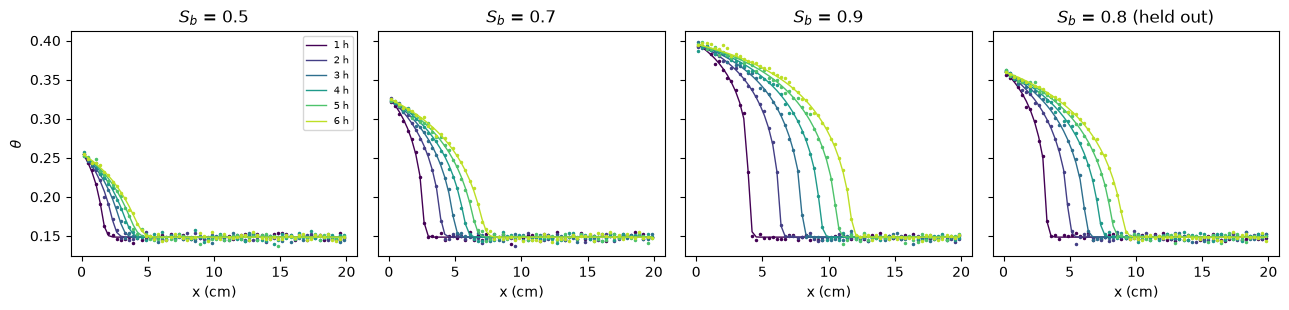

In [4]:
spec_true, wet, _ = soil_column(D_true)
problem_true = spec_true.build()
y0 = spec_true.assemble_state({})
solver = ds.JIDA(linear="klu")
ts = jnp.linspace(1.0, T, 6)                      # one profile per hour
S_b = jnp.array([0.5, 0.7, 0.9, 0.8])             # the last one is held out


def solve_one(s):
    theta = ds.default_theta(problem_true, {wet: to_theta(s)})
    return ds.pdesolve(problem_true, solver, (0.0, T), y0, theta=theta, saveat=ds.SaveAt(ts=ts)).ys


profiles = jax.jit(jax.vmap(solve_one))(S_b)
sigma = 0.003
data = profiles + sigma * np.random.default_rng(0).standard_normal(profiles.shape)

x = cartesian_grid_1d(N, 0.0, L).coordinates[0]  # cell centres
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
colors = plt.cm.viridis(np.linspace(0.0, 0.9, len(ts)))
for k, ax in enumerate(axes):
    for j, c in enumerate(colors):
        ax.plot(x, data[k, j], ".", ms=3, color=c)
        ax.plot(x, profiles[k, j], color=c, lw=1, label=f"{ts[j]:.0f} h")
    ax.set_title(f"$S_b$ = {S_b[k]:.1f}" + (" (held out)" if k == 3 else ""))
    ax.set_xlabel("x (cm)")
axes[0].set_ylabel(r"$\theta$")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

The wetter the end, the farther the front travels, since $D$ rises steeply with moisture.

## A network for the diffusivity

We represent the unknown $D$ by a multilayer perceptron with two hidden layers of 32 units. A small Equinox module feeds it $S$ mapped onto $[-1, 1]$, where the tanh units respond, and exponentiates its output so that $D$ stays positive. With `learnable=True`, a fit can move every weight ([function approximation](../overview/inference/function-approximation.md)).

In [5]:
class Diffusivity(eqx.Module):
    mlp: eqx.nn.MLP

    def __call__(self, S):
        return jnp.exp(self.mlp(2 * S - 1))       # the network returns log D


net = eqx.nn.MLP("scalar", "scalar", width_size=32, depth=2, activation=jnp.tanh, key=jax.random.PRNGKey(0))
spec_nn, wet_nn, D_nn = soil_column(Diffusivity(net), learnable=True)
problem_nn = spec_nn.build()
print(f"{sum(w.size for w in jax.tree.leaves(eqx.filter(net, eqx.is_array)))} weights")

1153 weights


Each experiment pairs one data set with one solve, and `inputs=` fixes the wet-end value for that experiment alone ([fitting parameters](../overview/inference/fitting.md#declare-the-experiment)). With the weight $1/\sigma^2$, a fit that matches the data to the noise has a loss of about half the number of data points.

In [6]:
def experiment(k):
    measurement = ds.inference.Measurement("theta", ts, data[k], weight=1 / sigma**2)
    return ds.inference.Experiment(problem_nn, solver, (0.0, T), y0, (measurement,), inputs={"theta_b": to_theta(S_b[k])})


print(f"noise level of the loss: about {data[0].size // 2} per experiment")

noise level of the loss: about 192 per experiment


## Train on one experiment

We start with the middle experiment, $S_b = 0.7$, and train with Adam, a standard gradient-based optimizer, and a decaying step size through `ds.inference.Optax` ([optimization solvers](../overview/inference/solvers.md#optax)). The gradient comes from reverse mode in one backward pass for all the weights, where forward mode would push one tangent per weight ([sensitivities](../overview/simulation/sensitivities.md#reverse-mode-and-checkpointing)).

In [7]:
def train(experiments):
    infproblem = ds.inference.InferenceProblem(experiments, parameters=D_nn)
    adam = optax.adam(optax.cosine_decay_schedule(2e-2, STEPS, alpha=0.05))
    result = ds.inference.optsolve(infproblem, ds.inference.Optax(adam, max_steps=STEPS))
    print(f"{result.n_steps} steps in {result.wall_time:.0f} s, loss {result.cost_history[0]:.3g} -> {result.cost:.3g}")
    return result[D_nn]


net_one = train((experiment(1),))

400 steps in 31 s, loss 1.75e+04 -> 200


The loss falls from $1.75 \times 10^4$ to 200, close to the noise level of 192.

## Check against the true diffusivity

To check the network, we compare $D$ with the truth at five saturations and predict the held-out experiment, passing the trained network to `ds.default_theta` as the value of `D_nn`.

In [8]:
S_check = jnp.array([0.3, 0.5, 0.7, 0.8, 0.9])


def report(network):
    for s, d, d_true in zip(S_check, jax.vmap(network)(S_check), D_true(S_check)):
        print(f"S = {s:.1f}: D = {d:6.2f} cm^2/h, truth {d_true:6.2f}, error {100 * (d / d_true - 1):+4.0f}%")
    theta = ds.default_theta(problem_nn, {D_nn: network, wet_nn: to_theta(S_b[3])})
    prediction = ds.pdesolve(problem_nn, solver, (0.0, T), y0, theta=theta, saveat=ds.SaveAt(ts=ts)).ys
    print(f"held-out error {jnp.sqrt(jnp.mean((prediction - data[3]) ** 2)):.4f}, noise {sigma}")
    return prediction


pred_one = report(net_one)

S = 0.3: D =   0.33 cm^2/h, truth   0.37, error  -12%
S = 0.5: D =   2.40 cm^2/h, truth   2.26, error   +6%
S = 0.7: D =   7.69 cm^2/h, truth   9.15, error  -16%
S = 0.8: D =   9.61 cm^2/h, truth  18.78, error  -49%
S = 0.9: D =  10.72 cm^2/h, truth  45.95, error  -77%


held-out error 0.0115, noise 0.003


From $S = 0.3$ up to $0.7$, the wettest soil this experiment reached, the network is within 16% of the truth. Above it the data say nothing about $D$, and the network flattens out, 77% low at $S = 0.9$. The held-out experiment at $S_b = 0.8$ needs $D$ in that range, so its prediction misses the data by almost four times the noise.

## Fit several experiments together

Experiments with different wet ends visit different parts of the curve. We therefore train one network on all three with a single `InferenceProblem`.

In [9]:
net_all = train(tuple(experiment(k) for k in range(3)))
pred_all = report(net_all)

400 steps in 189 s, loss 1.85e+05 -> 563
S = 0.3: D =   0.34 cm^2/h, truth   0.37, error   -9%
S = 0.5: D =   2.29 cm^2/h, truth   2.26, error   +1%
S = 0.7: D =   9.31 cm^2/h, truth   9.15, error   +2%
S = 0.8: D =  20.15 cm^2/h, truth  18.78, error   +7%
S = 0.9: D =  38.16 cm^2/h, truth  45.95, error  -17%
held-out error 0.0033, noise 0.003


With all three experiments, the network is within 9% of the truth from $S = 0.3$ to $0.8$ and 17% low at $S = 0.9$, the edge of the data. The held-out prediction now misses the data by little more than the noise. Training on three experiments took about six times as long as on one.

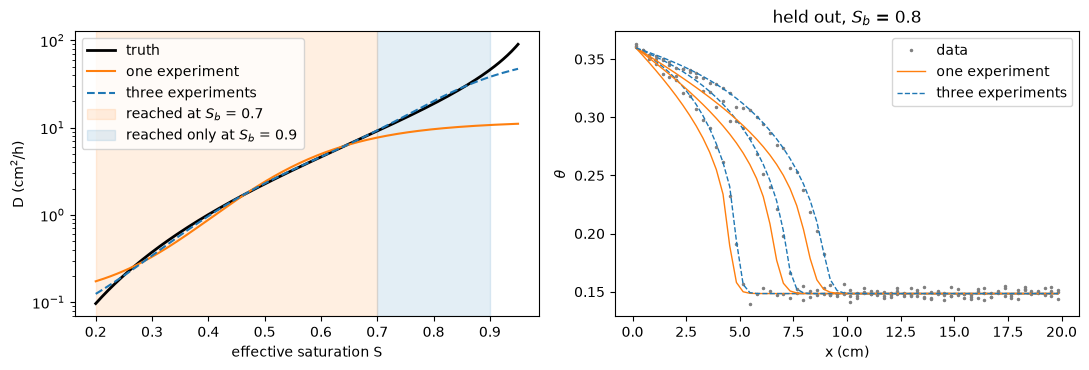

In [10]:
S = jnp.linspace(0.2, 0.95, 200)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.semilogy(S, D_true(S), "k", lw=2, label="truth")
ax1.semilogy(S, jax.vmap(net_one)(S), "C1", label="one experiment")
ax1.semilogy(S, jax.vmap(net_all)(S), "C0--", label="three experiments")
ax1.axvspan(S_i, 0.7, color="C1", alpha=0.12, label="reached at $S_b$ = 0.7")
ax1.axvspan(0.7, 0.9, color="C0", alpha=0.12, label="reached only at $S_b$ = 0.9")
ax1.set(xlabel="effective saturation S", ylabel=r"D (cm$^2$/h)")
ax1.legend()
for j in (1, 3, 5):
    ax2.plot(x, data[3, j], ".", ms=3, color="0.5", label="data" if j == 1 else None)
    ax2.plot(x, pred_one[j], "C1", lw=1, label="one experiment" if j == 1 else None)
    ax2.plot(x, pred_all[j], "C0--", lw=1, label="three experiments" if j == 1 else None)
ax2.set(xlabel="x (cm)", ylabel=r"$\theta$", title="held out, $S_b$ = 0.8")
ax2.legend()
plt.tight_layout()
plt.show()

On the left, the network trained on one experiment leaves the truth where its data end. On the right, at 2, 4 and 6 h, its held-out fronts lag behind the data, while the fronts of the network trained on three sit on them.

## Going to 2D

Next, we reuse the trained network in 2D, both to time larger solves and to predict a front the network has never seen. The same soil fills a horizontal layer of 20 cm by 20 cm, wetted along a 4 cm stretch of one edge and closed elsewhere. `cartesian_grid_2d` gives a square grid and `grid.meshgrid()` its cell centres, from which we pick the edge cells within 2 cm of the middle.

In [11]:
def soil_layer(diffusivity, n, learnable=False):
    grid = cartesian_grid_2d(n, n, L, L)
    X, Y = (np.ravel(a) for a in grid.meshgrid())  # cell centres, in field order
    spec = ds.problem("soil_layer")
    spec.domain("layer", grid)
    spec.field("theta", mass="differential", scale=1.0, init=lambda x, y: to_theta(S_i) + 0.0 * x)
    spec.function("D", diffusivity, learnable=learnable, pointwise=True)

    @spec.equation(writes="theta", reads=("theta",))
    def richards(q):
        return q.ops.div_flux(q.fn.D(saturation(q.theta)), q.theta)

    strip = np.flatnonzero((Y == Y.max()) & (np.abs(X - L / 2) < 2.0))
    spec.bc.dirichlet("theta", node_indices=strip, value=to_theta(0.8))
    return spec

We time one forward solve and one reverse-mode gradient with respect to the weights, in 1D and in 2D at several sizes. `jax.default_device` places each solve on the CPU with KLU or on the GPU with cuDSS. The gradient is of a squared misfit, so it costs what a training step costs, and each case runs once to compile before it is timed.

In [12]:
def seconds(f, *args):
    jax.block_until_ready(f(*args))               # the first call compiles
    start = time.perf_counter()
    jax.block_until_ready(f(*args))
    return time.perf_counter() - start


def time_case(spec, linear):
    problem, y0_case, case_solver = spec.build(), spec.assemble_state({}), ds.JIDA(linear=linear)
    theta = ds.default_theta(problem)

    def predicted(theta, adjoint=None):
        return ds.pdesolve(problem, case_solver, (0.0, T), y0_case, theta=theta, saveat=ds.SaveAt(ts=ts), adjoint=adjoint).ys

    misfit = lambda theta: jnp.sum((predicted(theta, ds.CheckpointAdjoint()) - to_theta(0.5)) ** 2)
    return seconds(eqx.filter_jit(predicted), theta), seconds(eqx.filter_jit(eqx.filter_grad(misfit)), theta)

In [13]:
devices = [("CPU", CPU, "klu")] + ([("GPU", jax.devices("gpu")[0], "cudss")] if GPU else [])
builders = {1: lambda n: soil_column(net_all, True, n)[0], 2: lambda n: soil_layer(net_all, n, True)}
print(f"{'cells':>19}" + "".join(f"{name + ' solve':>14}{name + ' grad':>14}" for name, _, _ in devices))
for dim, sizes in SIZES.items():
    for n in sizes:
        row = f"{dim}D {' x '.join([str(n)] * dim):>9} {n**dim:>6}"
        for name, device, linear in devices:
            if name == "CPU" and n**dim > 128**2:        # too slow to wait for
                row += f"{'-':>14}{'-':>14}"
                continue
            with jax.default_device(device):
                row += "".join(f"{t:12.3f} s" for t in time_case(builders[dim](n), linear))
        print(row)

              cells     CPU solve      CPU grad     GPU solve      GPU grad


1D        64     64       0.018 s       0.112 s       0.181 s       1.177 s


1D       256    256       0.073 s       0.431 s       0.314 s       1.947 s


1D      1024   1024       0.354 s       1.895 s       0.555 s       3.562 s


2D   32 x 32   1024       0.083 s       0.580 s       0.160 s       0.984 s


2D   64 x 64   4096       0.387 s       3.703 s       0.283 s       1.953 s


2D 128 x 128  16384       3.036 s      25.124 s       0.771 s       4.986 s


2D 256 x 256  65536             -             -       2.714 s      18.416 s


In 1D the CPU beats the GPU at every size, by about ten times at 64 cells, which is why the 1D training runs on the CPU. In 2D the GPU pulls ahead from 64 by 64 cells and is four to five times faster at 128 by 128.

Finally, we let the network trained on 1D profiles predict the 2D front at 64 by 64 cells and compare it with the true law after six hours.

largest difference in theta: 0.0039


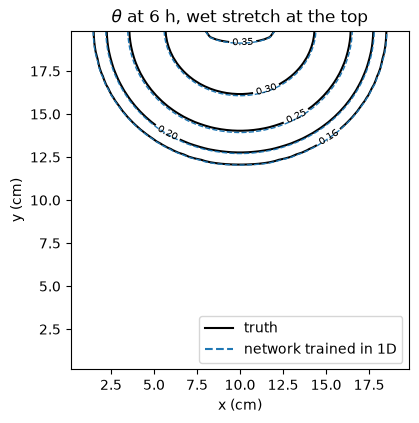

In [14]:
n2 = 64
fronts = {}
for label, diffusivity in (("truth", D_true), ("network", net_all)):
    spec = soil_layer(diffusivity, n2)
    sol = ds.pdesolve(spec.build(), solver, (0.0, T), spec.assemble_state({}), saveat=ds.SaveAt(ts=ts))
    fronts[label] = sol.ys[-1].reshape(n2, n2).T            # rows along y
print(f"largest difference in theta: {jnp.max(jnp.abs(fronts['network'] - fronts['truth'])):.4f}")

xs, ys = cartesian_grid_2d(n2, n2, L, L).coordinates
fig, ax = plt.subplots(figsize=(5, 4.4))
levels = [0.16, 0.2, 0.25, 0.3, 0.35]
ax.clabel(ax.contour(xs, ys, fronts["truth"], levels=levels, colors="k", linewidths=1.5), fontsize=7)
ax.contour(xs, ys, fronts["network"], levels=levels, colors="C0", linestyles="--", linewidths=1)
ax.plot([], [], "k", label="truth")
ax.plot([], [], "C0--", label="network trained in 1D")
ax.set(xlabel="x (cm)", ylabel="y (cm)", aspect="equal", title=r"$\theta$ at 6 h, wet stretch at the top")
ax.legend(loc="lower right")
plt.show()

The contours of the network lie on the true ones, and the largest difference in $\theta$, 0.004, is close to the noise in the 1D data. Since $D$ depends on $S$ alone, a diffusivity learned in 1D carries over to the 2D layer unchanged.